# Diffusion histograms
Set `data_dir` to the folder with the cleaned CSVs (`*_clean.csv`) and run the cell. One SVG per condition is saved in this notebook's folder.

15 °C: 6168 tracks, median Dapp = 0.229 µm²/s -> tracks_exp_Dapp_histogram.svg


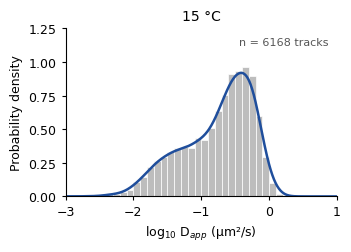

In [3]:
# ---------------------------------------------------------------- settings
import os
data_dir = r"\\home.org.aalto.fi\tomase1\data\Documents\Aalto\microscopy data\40gem_ecoli_15deg_21.10.26"     # folder with the *_clean.csv files
conditions = [                                      # (file name, title on the plot)
    ("tracks_exp_4c06a400_a_d61def66.csv",       "15 °C"),
    #("clpx_32HS_5min_clean.csv",   "32 °C, 5 min"),
    #("clpx_32HS_15min_clean.csv",  "32 °C, 15 min"),
    #("clpx_22REC_5min_clean.csv",  "Recovery 5 min"),
    #("clpx_22REC_15min_clean.csv", "Recovery 15 min"),
    #("clpx_22REC_30min_clean.csv", "Recovery 30 min"),
]
bin_width = 0.1           # histogram bin width, in log10 units
x_range   = (-3, 1.0)     # x-axis limits (log10 µm²/s)
y_max     = 1.25           # same y-axis for every plot, so they can be compared; None = automatic
kde_bw    = 0.11          # KDE smoothing: None = automatic; e.g. 0.15 = smoother, 0.07 = more detail

# ---------------------------------------------------------------- code
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import gaussian_kde

HIST_COLOR, KDE_COLOR = "#BDBDBD", "#1F4E9C"
plt.rcParams.update({"font.family": "DejaVu Sans", "font.size": 9, "svg.fonttype": "none"})
KEY = ["fov_mask_id", "cell_id_int", "particle"]          # one track = these three together

for fname, title in conditions:
    df = pd.read_csv(os.path.join(data_dir, fname))
    logD = np.log10(df.groupby(KEY)["Dapp"].first().to_numpy())   # one Dapp per track

    fig, ax = plt.subplots(figsize=(3.5, 2.6))
    bins = np.arange(x_range[0], x_range[1] + bin_width, bin_width)
    ax.hist(logD, bins=bins, density=True, color=HIST_COLOR, edgecolor="white", linewidth=0.5)
    kde = gaussian_kde(logD, bw_method=None if kde_bw is None else kde_bw / logD.std(ddof=1))
    xs = np.linspace(*x_range, 500)
    ax.plot(xs, kde(xs), color=KDE_COLOR, lw=1.8)

    ax.set_xlim(*x_range)
    ax.set_ylim(0, y_max)
    ax.set_xlabel(r"log$_{10}$ D$_{app}$ (µm²/s)")
    ax.set_ylabel("Probability density")
    ax.set_title(title, fontsize=10)
    ax.text(0.97, 0.95, f"n = {len(logD)} tracks", transform=ax.transAxes,
            ha="right", va="top", fontsize=8, color="#555555")
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    ax.tick_params(direction="out", length=3)
    fig.tight_layout()

    out = fname.replace("_4c06a400_a_d61def66.csv", "_Dapp_histogram.svg")
    fig.savefig(out, bbox_inches="tight")                  # saved in the notebook's folder
    print(f"{title}: {len(logD)} tracks, median Dapp = {10 ** np.median(logD):.3f} µm²/s -> {out}")
    plt.show()
